# <시각화 및 특성(feature) 엔지니어링>
 0. 용어정의 : 컬럼 = 항목 = 특성 = 퓨처(feature) 모두 같은 의미
 1. 단일 변수(수치형/범주형) 분포 시각화 및 특성 파악
 2. 다변량 상관관계 분석 및 통계적 유의성(p-value) 검증
 3. 분석 목적에 따른 범주형 데이터 인코딩(문자 -> 숫자) (Label, One-Hot)
 4. 수치형 데이터 스케일링 (Standard, MinMax, Robust)
 5. 비즈니스 로직 기반 파생변수(새로운 특성(feature)) 생성
 6. 타겟(target=종속=정답) 변수(Churn 고객이탈 여부 특성) 클래스 불균형 확인 및 시각화
 7. SMOTE 기법을 활용한 오버샘플링 및 불균형 해소
   - K-최근접 이웃(KNN) 알고리즘 원리를 기반으로
     소수(작은 데이터) 클래스(이탈 고객)의 데이터를 가상으로 증식시켜
     클래스(target) 비율을 1:1로 맞추기
 8. 모델 학습을 위한 훈련(학습용)/검증(튜닝용)/테스트(최종 평가용) 데이터 = 6:2:2 분리


## 1. 단일 변수(수치형/범주형) 분포 시각화 및 특성 파악

In [2]:
### 사용할 라이브러리 불러들이기

# 데이터 조작을 위한 라이브러리
import pandas as pd

# 기본 시각화 라이브러리
import matplotlib.pyplot as plt

# 통계적 시각화 라이브러리(보통 기본 시각화보다 향상된 라이브러리라고 생각하면 됨)
import seaborn as sns

# 시각화 시 그래프의 너비/높이 기본 설정하기(단위=인치)
plt.rcParams["figure.figsize"] = (12, 5)

# 시각화시 한글 깨짐 처리를 위한 폰트 지정(Window OS 기준, Mac OS나 Linux는 그에 맞게)
plt.rcParams['font.family'] = 'Malgun Gothic'

# 시각화시 마이너스(-) 기호 깨짐 방지 처리
plt.rcParams['axes.unicode_minus'] = False

#### 사용할 데이터셋 읽어들이기(전처리 완료 파일)

In [3]:
### 데이터셋 읽어들이고, 변수명은 df로 받아오기

df = pd.read_csv("./dataset/01_03_clean_ecommerce_data_clean.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4982 entries, 0 to 4981
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   CustomerID      4982 non-null   int64  
 1   Age             4982 non-null   int64  
 2   Gender          4982 non-null   object 
 3   Tenure          4982 non-null   int64  
 4   MonthlyCharges  4982 non-null   float64
 5   TotalCharges    4982 non-null   float64
 6   SupportCalls    4982 non-null   int64  
 7   ReviewScore     4982 non-null   float64
 8   Churn           4982 non-null   int64  
dtypes: float64(3), int64(5), object(1)
memory usage: 350.4+ KB


##### 수치형 데이터(나이, 가입기간)에 대한 분포 확인하기(시각화-히스토그램)

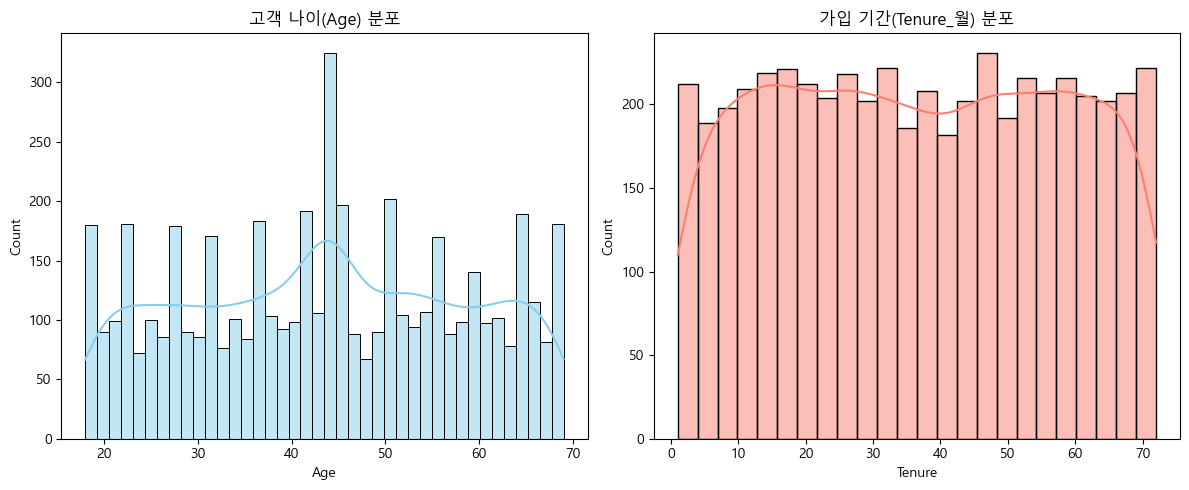

In [20]:
### 하나의 그래프에 여러 그래프 그리기

# 하나의 그래프 내에 공간(행렬) 만들기
fig, axes = plt.subplots(1, 2) #(1행, 2열)

# - 첫번째 axes[0]번째 고객 나이(Age) 분포를 히스토그램으로 시각화
# -> kde=True 지정 : 커널 밀도 추정 곡선을 함께 그리기
# -> bins : 막대 너비 사이즈 조정
sns.histplot(df["Age"], bins=40, kde=True, ax=axes[0], color="skyblue")

# 첫번째 그래프의 제목 넣기
axes[0].set_title("고객 나이(Age) 분포")

# 두번째 axes[1]번째에 서비스 가입 기간(Tenure) 분포를 시각화 하기
sns.histplot(df["Tenure"], bins=24, kde=True, ax=axes[1], color='salmon')
# 두번째 그래프의 제목 넣기
axes[1].set_title("가입 기간(Tenure_월) 분포")

### 서브플롯(여러개의 그래프를 하나의 그래프로)으로 시각화 시에는 항상 마지막에 레이아웃 자동 조정 함수 넣기
# - 행이 많아지는 경우 위/아래 행의 그래프가 겹쳐서 보여지게되어 이를 자동 조정해야함.
plt.tight_layout()

# 시각화 그래프를 보여주고, 시각화에 사용된 메모리 삭제하기(초기화)
plt.show()

##### 범주형 데이터(성별)의 분포 확인하기(시각화 - 막대그래프-countplot 사용)

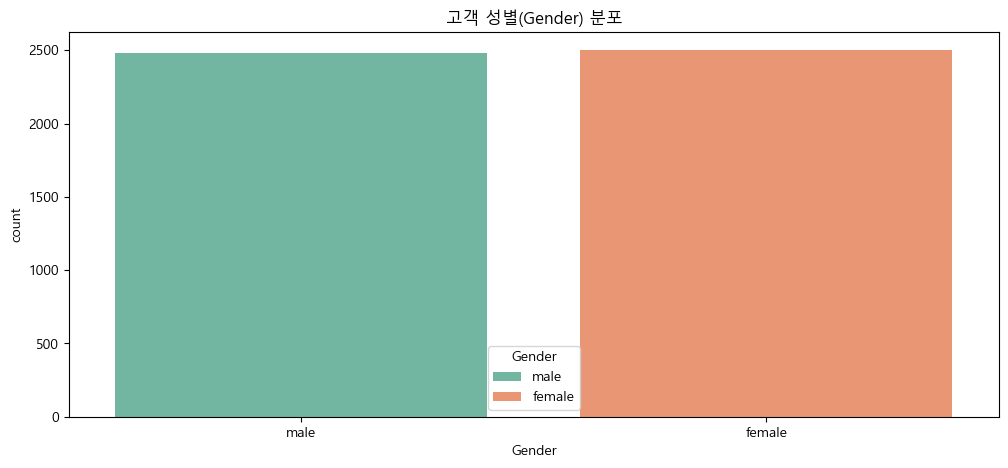

In [25]:
plt.title("고객 성별(Gender) 분포")
# - hue : count에 사용할 컬럼 지정
# - palette : 막대 색상 설정
# - legend : 범례 표시
sns.countplot(data=df, x="Gender", hue="Gender", palette="Set2", legend=True)
plt.show()

## 범주 데이터에 대한 확인은 편차가 있는지 확인...(편향(bias) 유무 확인)

## 2. 다변량 상관관계 분석 및 통계적 유의성(p-value) 검증
- 두 개 이상의 수치형 변수(컬럼, 항목, 특성(feature)) 간의 선형적 연관성(상관계수)을
- 수치 및 히트맵으로 시각화하고,
- 통계적 가설 검정(p-value)을 통해
- => 이 변수 간의 상관관계가 우연인지 유의미한지 판단함
- => 유의미한 변수들을 찾는 과정임. 즉 모델 훈련에 사용할 특성을 찾는 과정





##### 사용할 라이브러리 불러들이기

In [4]:
### 유의미성(p-value)을 확인하기 위한 라이브러리(통계 라이브러리라고도 칭함)
# - 유의미성 확인 방법 : 피어슨 및 스피어만 방식을 사용
from scipy import stats

##### Pandas의 DataFrame을 이용한 전체 수치형 변수 간의 상관행렬표(Correlation Matrix) 확인하기

In [6]:
### 데이터프레임에서 수치형(number) 데이터만 먼저 추출하기(범주형 데이터는 제외)
number_df = df.select_dtypes(include=["number"])
number_df

### 상관행렬표 확인하기 -> 피어슨(pearson) 방식 사용
# - corr() : 상관행렬표(Correlation Matrix) 함수
corr_matrix = number_df.corr(method="pearson")
corr_matrix

### 수치값 해석 방법
# 값의 범위 : 1 ~ -1
# 1 : 완벽한 [양의 상관관계] = 우상향 = 비례
# 0 : 상관없음
# -1 : 완벽한 [음의 상관관계] = 우하향 = 반비례

# *** 절대값으로 해석하면 됨

,CustomerID,Age,Tenure,MonthlyCharges,TotalCharges,SupportCalls,ReviewScore,Churn
CustomerID,1.000000,-0.011954,0.002670,0.009346,0.000061,-0.011186,-0.019483,0.004344
Age,-0.011954,1.000000,-0.011080,-0.018030,-0.019990,0.016469,-0.007549,-0.000111
Tenure,0.002670,-0.011080,1.000000,-0.031537,0.640298,0.017594,-0.028013,-0.088982
MonthlyCharges,0.009346,-0.018030,-0.031537,1.000000,0.552044,0.017908,0.009155,0.007551
TotalCharges,0.000061,-0.019990,0.640298,0.552044,1.000000,0.020298,-0.014573,-0.059603
SupportCalls,-0.011186,0.016469,0.017594,0.017908,0.020298,1.000000,0.026480,0.263716
ReviewScore,-0.019483,-0.007549,-0.028013,0.009155,-0.014573,0.026480,1.000000,-0.257427
Churn,0.004344,-0.000111,-0.088982,0.007551,-0.059603,0.263716,-0.257427,1.000000


##### 상관행렬표를 시각화하기(상관행렬도 그리기 - 히트맵 그래프 사용)

<function matplotlib.pyplot.show(close=None, block=None)>

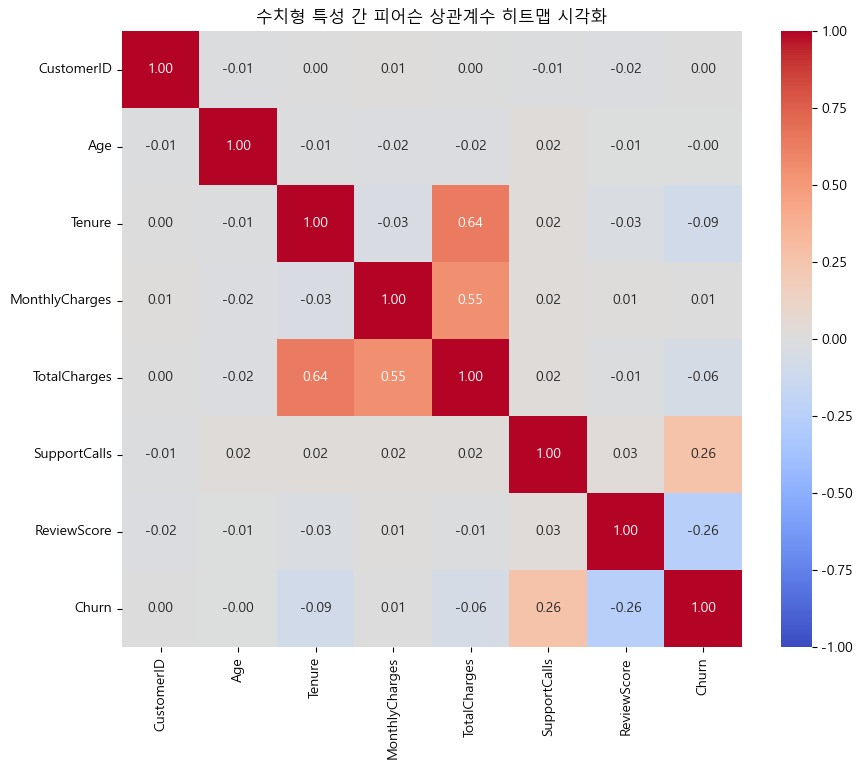

In [10]:
### 그래프 가로/세로 사이즈 조정
plt.figure(figsize=(10,8))

### 히트맵 그래프 그리기
#  - annot=True: 박스 안에 수치 표시,
#  - fmt='.2f': 소수점 둘째 자리까지 표시,
#  - cmap='coolwarm': 한랭/온난 색상 맵 적용
#  - vmin/vmax : 히트맵의 색상 막대(Colorbar)가 표현할 최소값과 최대값을 고정하는 값
plt.title('수치형 특성 간 피어슨 상관계수 히트맵 시각화')
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)

plt.show

##### 특정 변수간에 상관관계에 대한 유의미성(p-value) 검증
<유의미성(p-value) 검증 방법>
- 피어슨 검증 방법(가장 많이 검증 되는 방법)
- 스피어만 검증 방법(데이터 방식 불규칙, 범주형 등)

In [ ]:
### 피어슨 방식
# - 가입기간(Tenure)과 총결제액(TotalCharges) 강의
# 피어슨 상관관계 계수와 유의미계수(p-value) 계산하기
# - 유의미 계수(p-value)가 0.05보다 작다면 유의미하다고 판단
#                                  크면 유의미 하지 않다고 판단(우연의 일치)
# - 수식으로 표현하여 해석 : p-value < 0.05 이므로 유의미함
pearson_coef, p_value_pearson = stats.pearsonr(df["Tenure"], df["TotalCharges"]) #항상 두개씩 넣기
print(f"가입기간 vs 총결제액 상관관계 계수 = {pearson_coef: .3f} / p-value = {p_value_pearson}")
# p-value의 값이 0.05 미만이면 -> "가입기간(Tenure)과 총결제액(TotalCharges) 간의 관계는 유의미 합니다"ㅁ
# p-value의 값이 0.05 이상이면 -> "가입기간(Tenure)과 총결제액(TotalCharges) 간의 관계는 유의미 하지 않습니다"
if p_value_pearson < 0.05:
    print("가입기간(Tenure)과 총결제액(TotalCharges) 간의 관계는 유의미 합니다")
elif p_value_pearson >= 0.05:
    print("가입기간(Tenure)과 총결제액(TotalCharges) 간의 관계는 유의미 하지 않습니다")

가입기간 vs 총결제액 상관관계 계수 =  0.640 / p-value = 0.0
가입기간(Tenure)과 총결제액(TotalCharges) 간의 관계는 유의미 합니다


![alt text](image.png)

In [18]:
### 스피어만 방식
# - 리뷰점수(ReviewScore)와 월결제액(MonthlyCharges) 간의
#   스피어만 상관관계 계수와 유의미계수(p-value) 계산하기
# - 유의미 계수(p-value)가 0.05보다 작다면 유의미하다고 판단
#                                  크면 유의미 하지 않다고 판단(우연의 일치)
# - 수식으로 표현하여 해석 : p-value < 0.05 이므로 유의미함
spearman_coef, p_values_pearman = stats.spearmanr(df["ReviewScore"], df["MonthlyCharges"]) #항상 두개씩 넣기
print(f"가입기간 vs 총결제액 상관관계 계수 = {spearman_coef: .3f} / p-value = {p_values_pearman}")
# p-value의 값이 0.05 미만이면 -> "가입기간(Tenure)과 총결제액(TotalCharges) 간의 관계는 유의미 합니다"ㅁ
# p-value의 값이 0.05 이상이면 -> "가입기간(Tenure)과 총결제액(TotalCharges) 간의 관계는 유의미 하지 않습니다"
if p_values_pearman < 0.05:
    print("가입기간(Tenure)과 총결제액(TotalCharges) 간의 관계는 유의미 합니다")
elif p_values_pearman >= 0.05:
    print("가입기간(Tenure)과 총결제액(TotalCharges) 간의 관계는 유의미 하지 않습니다")

가입기간 vs 총결제액 상관관계 계수 =  0.009 / p-value = 0.5444216044189406
가입기간(Tenure)과 총결제액(TotalCharges) 간의 관계는 유의미 하지 않습니다


In [66]:
"""
"Churn" 컬럼과 아래 6개의 컬럼들과 각각 피어슨 방식으로 p-value값을 확인하여 유의미한지 안한지 각각 출력해 주세요. 실행누르면 6개 출력물이 한번에 나오게
    "Age": 고객 나이 (int)
    "Tenure": 가입 기간_월단위 (int)
    "MonthlyCharges": 월 평균 결제액 (float)
    "TotalCharges": 총 결제액 (float)
    "SupportCalls": 고객센터 문의 횟수 (int)
    "ReviewScore": 리뷰 평균 점수 (float)
"""

columns = ["Age", "Tenure", "MonthlyCharges", "TotalCharges", "SupportCalls", "ReviewScore"]
names = ["고객 나이", "가입 기간 월단위", "월 평균 결제액", "총 결제액", "고객센터 문의 횟수", "리뷰 평균 점수"]


for n in names:
    for i in columns:
        pearson_coef, p_value_pearson = stats.pearsonr(df["Churn"], df[i]) #항상 두개씩 넣기
        print(f"이탈(Churn) vs {n}{i} 상관관계 계수 = {pearson_coef: .3f} / p-value = {p_value_pearson: .20f}")
        if p_value_pearson < 0.05:
            print(f"이탈(Churn)과 {n}{i} 간의 관계는 유의미 합니다")
        elif p_value_pearson >= 0.05:
            print(f"이탈(Churn)과 {n}{i} 간의 관계는 유의미 하지 않습니다")
        if n == "리뷰 평균 점수":
            break

이탈(Churn) vs 고객 나이Age 상관관계 계수 = -0.000 / p-value =  0.99376702324235588470
이탈(Churn)과 고객 나이Age 간의 관계는 유의미 하지 않습니다
이탈(Churn) vs 고객 나이Tenure 상관관계 계수 = -0.089 / p-value =  0.00000000031437449818
이탈(Churn)과 고객 나이Tenure 간의 관계는 유의미 합니다
이탈(Churn) vs 고객 나이MonthlyCharges 상관관계 계수 =  0.008 / p-value =  0.59414701882740472705
이탈(Churn)과 고객 나이MonthlyCharges 간의 관계는 유의미 하지 않습니다
이탈(Churn) vs 고객 나이TotalCharges 상관관계 계수 = -0.060 / p-value =  0.00002557289713753908
이탈(Churn)과 고객 나이TotalCharges 간의 관계는 유의미 합니다
이탈(Churn) vs 고객 나이SupportCalls 상관관계 계수 =  0.264 / p-value =  0.00000000000000000000
이탈(Churn)과 고객 나이SupportCalls 간의 관계는 유의미 합니다
이탈(Churn) vs 고객 나이ReviewScore 상관관계 계수 = -0.257 / p-value =  0.00000000000000000000
이탈(Churn)과 고객 나이ReviewScore 간의 관계는 유의미 합니다
이탈(Churn) vs 가입 기간 월단위Age 상관관계 계수 = -0.000 / p-value =  0.99376702324235588470
이탈(Churn)과 가입 기간 월단위Age 간의 관계는 유의미 하지 않습니다
이탈(Churn) vs 가입 기간 월단위Tenure 상관관계 계수 = -0.089 / p-value =  0.00000000031437449818
이탈(Churn)과 가입 기간 월단위Tenure 간의 관계는 유의미 합니다
이탈(Chu

In [6]:
columns = {"Age": "고객 나이",
           "Tenure" : "가입 기간 월단위",
           "MonthlyCharges" : "월 평균 결제액",
           "TotalCharges" : "총 결제액",
           "SupportCalls" : "고객센터 문의횟수",
           "ReviewScore" : "리뷰 평균 점수"}

for k, v in columns.items():
    pearson_coef, p_value_pearson = stats.pearsonr(df["Churn"], df[k]) #항상 두개씩 넣기
    print(f"이탈여부(Churn) vs {v}({k}) \n상관관계 계수 = {pearson_coef: .3f} / p-value = {p_value_pearson}") # 이미 "" f스트링 안이라 ()가 문자열로 나온다.
    if p_value_pearson < 0.05:
        print(f"이탈여부(Churn)과 {v}({k}) 간의 관계는 유의미 합니다.\n")
    else:
        print(f"이탈여부(Churn)과 {v}({k}) 간의 관계는 유의미 하지 않습니다. \n")

이탈여부(Churn) vs 고객 나이(Age) 
상관관계 계수 = -0.000 / p-value = 0.9937670232423559
이탈여부(Churn)과 고객 나이(Age) 간의 관계는 유의미 하지 않습니다. 

이탈여부(Churn) vs 가입 기간 월단위(Tenure) 
상관관계 계수 = -0.089 / p-value = 3.143744981774314e-10
이탈여부(Churn)과 가입 기간 월단위(Tenure) 간의 관계는 유의미 합니다.

이탈여부(Churn) vs 월 평균 결제액(MonthlyCharges) 
상관관계 계수 =  0.008 / p-value = 0.5941470188274047
이탈여부(Churn)과 월 평균 결제액(MonthlyCharges) 간의 관계는 유의미 하지 않습니다. 

이탈여부(Churn) vs 총 결제액(TotalCharges) 
상관관계 계수 = -0.060 / p-value = 2.5572897137539078e-05
이탈여부(Churn)과 총 결제액(TotalCharges) 간의 관계는 유의미 합니다.

이탈여부(Churn) vs 고객센터 문의횟수(SupportCalls) 
상관관계 계수 =  0.264 / p-value = 4.799764120680935e-80
이탈여부(Churn)과 고객센터 문의횟수(SupportCalls) 간의 관계는 유의미 합니다.

이탈여부(Churn) vs 리뷰 평균 점수(ReviewScore) 
상관관계 계수 = -0.257 / p-value = 3.1187873271899214e-76
이탈여부(Churn)과 리뷰 평균 점수(ReviewScore) 간의 관계는 유의미 합니다.



In [ ]:
cols = df.columns.drop(['CustomerID', 'Gender', 'Churn'])

for col in cols:
    pearson_coef, p_value_pearson = stats.pearsonr(df["Churn"], df[col])
    print(f"Churn vs {col} \n상관관계 계수 = {pearson_coef: .3f} / p-value = {p_value_pearson}")
    if p_value_pearson < 0.05:
        print(f"Churn과 {col} 간의 관계는 유의미 합니다 \n")
    else:
        print(f"Churn과 {col} 간의 관계는 유의미 하지 않습니다 \n")

Churn vs Age 
상관관계 계수 = -0.000 / p-value = 0.9937670232423559
Churn과 Age 간의 관계는 유의미 하지 않습니다 

Churn vs Tenure 
상관관계 계수 = -0.089 / p-value = 3.143744981774314e-10
Churn과 Tenure 간의 관계는 유의미 합니다 

Churn vs MonthlyCharges 
상관관계 계수 =  0.008 / p-value = 0.5941470188274047
Churn과 MonthlyCharges 간의 관계는 유의미 하지 않습니다 

Churn vs TotalCharges 
상관관계 계수 = -0.060 / p-value = 2.5572897137539078e-05
Churn과 TotalCharges 간의 관계는 유의미 합니다 

Churn vs SupportCalls 
상관관계 계수 =  0.264 / p-value = 4.799764120680935e-80
Churn과 SupportCalls 간의 관계는 유의미 합니다 

Churn vs ReviewScore 
상관관계 계수 = -0.257 / p-value = 3.1187873271899214e-76
Churn과 ReviewScore 간의 관계는 유의미 합니다 



## 3. 분석 목적에 따른 범주형 데이터 인코딩(문자 -> 숫자) (Label, One-Hot)

- 머신러닝 알고리즘은 텍스트를 연산할 수 없으므로, -> 문자형 데이터를 숫자로 변환해야 함

- 데이터의 성격(서열 유무)에 따라 라벨 인코딩과 원-핫 인코딩으로 구분하여 적용
```python
  -> 라벨 인코딩 예시 : 연령대 10, 20, 30 / 종류 0, 1, 2, 3 처럼 데이터 변환 (열에 있는 값만 바꾸는 것)
  -> 원-핫 인코딩 예시 : 성별 컬럼(특성)을 남자 컬럼(특성)과 여자 컬럼(특성)으로 `추가`하여 (메모리 차지 많아질 수 있음)
                        : 남자가 있는 행(row)의 경우에는
                        > 남자 컬럼(특성)에는 1 로, 여자 컬럼(특성)에는 0 으로 입력하여 데이터 변환
                        : 컬럼을 추가하여 학습에 유리하도록 처리하는 방법
```

##### 사용할 라이브러리 불러들이기

In [7]:
### 라벨인코딩 관련 라이브러리 불러들이기
from sklearn.preprocessing import LabelEncoder

In [ ]:
### 사용할 데이터를 복제하여 사용 (원본 훼손을 막기 위해서)
# - 복제의 의미 : 새로운 데이터프레임 메로리를 생성
df_encoded = df.copy()
df_encoded

,CustomerID,Age,Gender,Tenure,MonthlyCharges,TotalCharges,SupportCalls,ReviewScore,Churn
0,4,32,male,3,44.06,13888.00,4,4.6,1
1,10,40,female,15,36.90,50671.00,1,2.2,0
2,11,28,female,16,22.14,36716.00,5,1.2,1
3,22,47,male,54,117.37,6880.05,5,1.8,0
4,23,55,male,27,68.26,1736.67,0,2.3,0
...,...,...,...,...,...,...,...,...,...
4977,4996,24,male,17,131.19,2441.28,7,1.8,0
4978,4997,66,female,5,31.12,164.20,2,1.3,1
4979,4998,26,female,18,11.80,199.44,4,3.5,0
4980,4999,53,female,55,25.40,1455.62,5,2.6,0


##### 라벨 인코딩(Label Encoding) 처리하기 - Gender 데이터 처리

In [20]:
### 라벨인코딩 클래스 객체 사용해야함.
# - 라벨인코딩 클래스 LabelEncoder
le_gender = LabelEncoder()
le_gender

### Gender 성별 데이터의 범주에 대한 숫자로 변경하기 위한 패턴 찾기
# - 범주값을 스스로 찾아서 숫자로 변경하게끔 패턴 학습 시킴
# fit 패턴 찾아라
# fit_transform : 패턴 찾고 동시에 숫자로 바꿔라
df_encoded["Gender_Label"] = le_gender.fit_transform(df_encoded["Gender"])

### 라벨인코더가 찾아낸 범주들 추출
print(le_gender.classes_)

df_encoded.head()

['female' 'male']


,CustomerID,Age,Gender,Tenure,MonthlyCharges,TotalCharges,SupportCalls,ReviewScore,Churn,Gender_Label
0,4,32,male,3,44.06,13888.00,4,4.6,1,1
1,10,40,female,15,36.90,50671.00,1,2.2,0,0
2,11,28,female,16,22.14,36716.00,5,1.2,1,0
3,22,47,male,54,117.37,6880.05,5,1.8,0,1
4,23,55,male,27,68.26,1736.67,0,2.3,0,1


In [12]:
df_encoded["Gender"]

0         male
1       female
2       female
3         male
4         male
         ...  
4977      male
4978    female
4979    female
4980    female
4981    female
Name: Gender, Length: 4982, dtype: object

##### 라벨 인코딩(Label Encoding) 처리하기 - Gender 데이터 처리

In [244]:
### 원핫 인코딩을 위한 컬럼은 임의로 샘플 컬럼을 만들어서 해보겠습니다.
import numpy as np

### 멤버십(Membership)이라는 임의 샘플 컬럼 생성하기(데이터는 랜덤으로 생성)
# - len(df_encoded) 데이터프레임의 전체 행의 갯수만큼
# - 랜덤하게 값을 선택해서 처리
df_encoded["Membership"] = np.random.choice(["Basic", "Silver", "Gold"], size=len(df_encoded))
df_encoded.head(3)

,CustomerID,Age,Gender,Tenure,MonthlyCharges,TotalCharges,SupportCalls,ReviewScore,Churn,Gender_Label,Membership
0,4,32,male,3,44.06,13888.0,4,4.6,1,1,Gold
1,10,40,female,15,36.90,50671.0,1,2.2,0,0,Gold
2,11,28,female,16,22.14,36716.0,5,1.2,1,0,Gold


In [ ]:

### 원-핫 인코딩 처리하기 : 판다스 라이브러리의 get_dummies() 함수사용
# - Membership 원본 컬럼은 삭제되고, 범주값들이 컬럼으로 만들어짐
# - 컬럼명 이름 규칙 : 원본컬럼명_범주명
df_encoded = pd.get_dummies(df_encoded, columns=["Membership"], dtype=int)


# print(df_encoded["Membership"])
# df_encoded.info()
# df_encoded.head()

,CustomerID,Age,Gender,Tenure,MonthlyCharges,TotalCharges,SupportCalls,ReviewScore,Churn,Gender_Label,Membership_Basic,Membership_Gold,Membership_Silver
0,4,32,male,3,44.06,13888.00,4,4.6,1,1,0,1,0
1,10,40,female,15,36.90,50671.00,1,2.2,0,0,0,1,0
2,11,28,female,16,22.14,36716.00,5,1.2,1,0,0,1,0
3,22,47,male,54,117.37,6880.05,5,1.8,0,1,1,0,0
4,23,55,male,27,68.26,1736.67,0,2.3,0,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4977,4996,24,male,17,131.19,2441.28,7,1.8,0,1,1,0,0
4978,4997,66,female,5,31.12,164.20,2,1.3,1,0,0,0,1
4979,4998,26,female,18,11.80,199.44,4,3.5,0,0,0,0,1
4980,4999,53,female,55,25.40,1455.62,5,2.6,0,0,1,0,0


## 4. 수치형 데이터 스케일링 (Standard, MinMax, Robust)
``` text
데이터 분석 직무로 갈 시 면접 질문될 수 있음
<데이터 스케일링> ★
 - 서로 다른 단위와 범위를 가진 수치형 변수들(예: 10~70세 나이 vs 10000달러 결제액)을
   -> 모델이 동일한 비중으로 학습할 수 있도록 정규화/표준화하는 방법을 "데이터 스케일링" 이라고 칭함


** 표준화(Standardization)와 정규화(Normalization)
 - StandardScaler : 표준화(Standardization)
                  : 데이터의 분포(Distribution)를 중심성 위주로 정렬함
                  : 데이터를 평균이 0, 표준편차가 1인 고르게 분포된 형태로 변환함
                  : 음수(-)의 값이 나올수도 있음
                  : 이상치에 비교적 덜 민감함. (평균과 분산이 이동할 뿐 데이터 균형이 깨지지 않음)
                  : 현업에서 가장 많이 사용함(70%)
                    (보통 전처리가 선행되기에 대부분의 머신러닝 알고리즘과 수학적으로 가장 잘 맞고 안정적임)


 - MinMaxScaler   : 정규화 (Normalization)
                  : 데이터의 범위(Scale)를 제한함
                  : 데이터의 최솟값을 0, 최댓값을 1로 고정하여 [0, 1] 범위로 압축함
                  : 이상치에 매우 취약함. (특이값 하나 때문에 정상 데이터들이 좁은 구역으로 뭉침)
                  : 현업에서 두번째로 가끔 사용함(20%)
                    (이미지 데이터(0~255) 처리나 데이터의 최댓값/최솟값이 명확히 정해져 있을 때 사용함)
                   
 - RobustScaler   : 표준화의 변형 (이상치 최소화 방법)  
                  : 평균과 표준편차 대신 중앙값(Median)과 IQR(사분위수 범위)을 사용하여
                    -> 이상치(Outlier)의 영향을 최소화하는 표준화 기법
                  : 음수(-)의 값이 나올수도 있음
                  : 데이터에 말도 안 되게 크거나 작은 이상치(Outlier)가 불규칙하게 섞여 있을 때,
                    -> Standard나 MinMax를 쓰면 모델이 망가지므로
                    => RobustScaler를 최우선으로 선택
                  : 현업에서 드물게 사용함(10% 미만)
                    (금융 사기 탐지(Fraud) 또는 이상 거래 등 극단적인 아웃라이어(이상치 분석)가
                     핵심 데이터로 분석될 때 사용함)
```



In [249]:
### 스케일링에 필요한 라이브러리 불러들이기
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

In [250]:
### 스케일링할 데이터(특성)을 별도로 추출하기
# - 보통 연속형 데이터를 스케일링 처리함
scale_cols = ["Age", "Tenure", "MonthlyCharges", "TotalCharges"]
scale_cols

['Age', 'Tenure', 'MonthlyCharges', 'TotalCharges']

In [252]:
df_encoded[scale_cols]

,Age,Tenure,MonthlyCharges,TotalCharges
0,32,3,44.06,13888.00
1,40,15,36.90,50671.00
2,28,16,22.14,36716.00
3,47,54,117.37,6880.05
4,55,27,68.26,1736.67
...,...,...,...,...
4977,24,17,131.19,2441.28
4978,66,5,31.12,164.20
4979,26,18,11.80,199.44
4980,53,55,25.40,1455.62


In [258]:
### StandardScaler 사용하기
# 클래스 생성하기
std_scaler = StandardScaler()
std_scaler

# 특성들에 대해서 변경할 패턴 찾고 값 생성하기
std_scaler.fit_transform(df_encoded[scale_cols])

### 스케일링한 4개 컬럼의 값에 대하여 데이터프레임에 새로운 컬럼 추가하여 값 저장시키기
# - 새로운 컬럼 이름 규칙: "Age_std", "Tenure_std", "MonthlyCharges_std", "TotalCharges_std"
[col + "_std" for col in scale_cols]
# df_encoded[["Age_std", "Tenure_std", "MonthlyCharges_std", "TotalCharges_std"]] = std_scaler.fit_transform(df_encoded[scale_cols])
df_encoded[[col + "_std" for col in scale_cols]] = std_scaler.fit_transform(df_encoded[scale_cols])
df_encoded.head(1)

,CustomerID,Age,Gender,Tenure,MonthlyCharges,TotalCharges,SupportCalls,ReviewScore,Churn,Gender_Label,Membership,Age_std,Tenure_std,MonthlyCharges_std,TotalCharges_std
0,4,32,male,3,44.06,13888.0,4,4.6,1,1,Gold,-0.798188,-1.614153,-0.906058,4.368251


In [260]:
### MinMaxScaler 사용하기
# 클래스 생성하기
mn_scaler = MinMaxScaler()
mn_scaler

# 특성들에 대해서 변경할 패턴 찾고 값 생성하기
mn_scaler.fit_transform(df_encoded[scale_cols])

### 스케일링한 4개 컬럼의 값에 대하여 데이터프레임에 새로운 컬럼 추가하여 값 저장시키기
df_encoded[[col + "_mn" for col in scale_cols]] = mn_scaler.fit_transform(df_encoded[scale_cols])
df_encoded.head(5)

,CustomerID,Age,Gender,Tenure,MonthlyCharges,TotalCharges,SupportCalls,ReviewScore,Churn,Gender_Label,Membership,Age_std,Tenure_std,MonthlyCharges_std,TotalCharges_std,Age_mn,Tenure_mn,MonthlyCharges_mn,TotalCharges_mn
0,4,32,male,3,44.06,13888.00,4,4.6,1,1,Gold,-0.798188,-1.614153,-0.906058,4.368251,0.274510,0.028169,0.243212,0.273945
1,10,40,female,15,36.90,50671.00,1,2.2,0,0,Gold,-0.249156,-1.037903,-1.087076,19.013344,0.431373,0.197183,0.192055,1.000000
2,11,28,female,16,22.14,36716.00,5,1.2,1,0,Gold,-1.072704,-0.989882,-1.460236,13.457183,0.196078,0.211268,0.086596,0.724544
3,22,47,male,54,117.37,6880.05,5,1.8,0,1,Basic,0.231248,0.834908,0.947356,1.578047,0.568627,0.746479,0.767005,0.135616
4,23,55,male,27,68.26,1736.67,0,2.3,0,1,Basic,0.780280,-0.461653,-0.294236,-0.469782,0.725490,0.366197,0.416119,0.034092


In [261]:
### RobustScaler 사용하기
# 클래스 생성하기
rb_scaler = RobustScaler()
rb_scaler

# 특성들에 대해서 변경할 패턴 찾고 값 생성하기
rb_scaler.fit_transform(df_encoded[scale_cols])

### 스케일링한 4개 컬럼의 값에 대하여 데이터프레임에 새로운 컬럼 추가하여 값 저장시키기
df_encoded[[col + "_rb" for col in scale_cols]] = rb_scaler.fit_transform(df_encoded[scale_cols])
df_encoded.head(5)

,CustomerID,Age,Gender,Tenure,MonthlyCharges,TotalCharges,SupportCalls,ReviewScore,Churn,Gender_Label,...,MonthlyCharges_std,TotalCharges_std,Age_mn,Tenure_mn,MonthlyCharges_mn,TotalCharges_mn,Age_rb,Tenure_rb,MonthlyCharges_rb,TotalCharges_rb
0,4,32,male,3,44.06,13888.00,4,4.6,1,1,...,-0.906058,4.368251,0.274510,0.028169,0.243212,0.273945,-0.484848,-0.891892,-0.540962,3.496751
1,10,40,female,15,36.90,50671.00,1,2.2,0,0,...,-1.087076,19.013344,0.431373,0.197183,0.192055,1.000000,-0.161616,-0.567568,-0.648907,14.544181
2,11,28,female,16,22.14,36716.00,5,1.2,1,0,...,-1.460236,13.457183,0.196078,0.211268,0.086596,0.724544,-0.646465,-0.540541,-0.871431,10.352927
3,22,47,male,54,117.37,6880.05,5,1.8,0,1,...,0.947356,1.578047,0.568627,0.746479,0.767005,0.135616,0.121212,0.486486,0.564270,1.391978
4,23,55,male,27,68.26,1736.67,0,2.3,0,1,...,-0.294236,-0.469782,0.725490,0.366197,0.416119,0.034092,0.444444,-0.243243,-0.176119,-0.152788


In [ ]:
# 위 3개의 스케일링 클래스를 한번에 실행해서 처리될 수 있도록 처리해 주세요.


df_encoded2 = df_encoded.copy()

classes = {StandardScaler() : "_std2", MinMaxScaler() : "_mn2", RobustScaler() : "_rb2"}



for k, v in classes.items():
    scaler = k
    scale_cols = ["Age", "Tenure", "MonthlyCharges", "TotalCharges"]
    # 특성들에 대해서 변경할 패턴 찾고 값 생성하기
    scaler.fit_transform(df_encoded2[scale_cols])
    [col + v for col in scale_cols]
    df_encoded2[[col + v for col in scale_cols]] = scaler.fit_transform(df_encoded2[scale_cols])


display(df_encoded2.head(1)) #print or display 를 이용하여 표시해주기!
df_encoded2.info()


,CustomerID,Age,Gender,Tenure,MonthlyCharges,TotalCharges,SupportCalls,ReviewScore,Churn,Gender_Label,...,MonthlyCharges_std2,TotalCharges_std2,Age_mn2,Tenure_mn2,MonthlyCharges_mn2,TotalCharges_mn2,Age_rb2,Tenure_rb2,MonthlyCharges_rb2,TotalCharges_rb2
0,4,32,male,3,44.06,13888.0,4,4.6,1,1,...,-0.906058,4.368251,0.27451,0.028169,0.243212,0.273945,-0.484848,-0.891892,-0.540962,3.496751


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4982 entries, 0 to 4981
Data columns (total 35 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   CustomerID           4982 non-null   int64  
 1   Age                  4982 non-null   int64  
 2   Gender               4982 non-null   object 
 3   Tenure               4982 non-null   int64  
 4   MonthlyCharges       4982 non-null   float64
 5   TotalCharges         4982 non-null   float64
 6   SupportCalls         4982 non-null   int64  
 7   ReviewScore          4982 non-null   float64
 8   Churn                4982 non-null   int64  
 9   Gender_Label         4982 non-null   int64  
 10  Membership           4982 non-null   object 
 11  Age_std              4982 non-null   float64
 12  Tenure_std           4982 non-null   float64
 13  MonthlyCharges_std   4982 non-null   float64
 14  TotalCharges_std     4982 non-null   float64
 15  Age_mn               4982 non-null   f

In [ ]:
"""
위의 3개의 스케일링 클래스를 한번에 실행해서 처리될 수 있도록 처리해 주세요...
 - 컬럼명 규칠 : _std2, _min2, _rb2

"""

df_encoded2 = df_encoded.copy()

dict_= {"_std2" : StandardScaler(), "_mn2" : MinMaxScaler(), "_rb2" : RobustScaler()}

for c_nm, s in dict_.items():
    df_encoded2[[col + c_nm for col in scale_cols]] = s.fit_transform(df_encoded2[scale_cols])

df_encoded2.head(3)

NameError: name 'a_ss' is not defined